# Ridge y recomendador

Este notebook explica el código basado en las clases 08, 10 y 16, HDT3/HDT5 y Proyectos 1 y 2. Solo usa junio. Ejecutar antes `python -m src.train_ridge`. Ridge es un candidato.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from src.modeling_data import load_development, make_folds
from src.recommend import recommend
X, y, metadata = load_development()
print(f'{len(X):,} anuncios; {metadata.host_id.nunique():,} anfitriones')
print('Predictores sin imputar:')
display(X.head())

Matplotlib is building the font cache; this may take a moment.


29,637 anuncios; 13,095 anfitriones
Predictores sin imputar:


,latitude,longitude,accommodates,bathrooms,bedrooms,beds,amenities_count,minimum_nights,maximum_nights,neighbourhood_cleansed,property_type,room_type,host_has_profile_pic,host_identity_verified
0,19.441832,-99.195921,4,NaN,2.0,NaN,35.0,2.0,730.0,Miguel Hidalgo,Entire rental unit,Entire home/apt,NaN,NaN
1,19.390737,-99.174752,2,3.0,1.0,1.0,33.0,1.0,120.0,Benito Juárez,Private room in guesthouse,Private room,t,t
2,19.443060,-99.162716,3,1.0,1.0,1.0,50.0,2.0,1125.0,Cuauhtémoc,Entire rental unit,Entire home/apt,t,t
3,19.406300,-99.162220,2,1.0,NaN,1.0,33.0,1.0,1125.0,Cuauhtémoc,Private room in rental unit,Private room,t,t
4,19.436377,-99.129178,3,1.0,1.0,2.0,35.0,2.0,1125.0,Cuauhtémoc,Entire loft,Entire home/apt,t,t


## Separar primero, aprender después

Como en Feature Engineering y Proyecto 1, el escalador aprende con entrenamiento. Aquí también aprenden allí la mediana de imputación y las categorías raras. Los anuncios del mismo anfitrión permanecen juntos. Los identificadores nunca son predictores.

In [2]:
folds = make_folds(metadata)
rows = []
for i, (train, valid) in enumerate(folds):
    overlap = set(metadata.host_id.iloc[train]) & set(metadata.host_id.iloc[valid])
    assert not overlap
    rows.append({'fold': i, 'entrenamiento': len(train), 'validacion': len(valid), 'anfitriones_compartidos': len(overlap)})
display(pd.DataFrame(rows))

,fold,entrenamiento,validacion,anfitriones_compartidos
0,0,23709,5928,0
1,1,23709,5928,0
2,2,23710,5927,0
3,3,23710,5927,0
4,4,23710,5927,0


## Ridge y calibración

Ridge minimiza el error cuadrático sobre log(precio) más alpha por la suma de coeficientes al cuadrado. La penalización reduce coeficientes inestables. Se escalan variables numéricas y se codifican categorías.

Dentro de cada entrenamiento se forman tres particiones adicionales. Cada fila recibe una predicción de un modelo que no la vio. Calculamos residuos log(precio) menos predicción y sus cuantiles 10, 35, 50 y 90. Finalmente ajustamos Ridge sobre ese entrenamiento completo. Para un anuncio nuevo usamos exp(predicción + cuantil del residuo).

Los desplazamientos globales están ordenados y no generan cruces. Son una aproximación: no modelan cómo cambia la dispersión según la zona o el tipo de alojamiento y no garantizan cobertura individual. Se pasa `groups=metadata.host_id.iloc[train]` a fit; sin groups hay compatibilidad por filas, pero esa alternativa no es la usada en nuestros resultados.

In [3]:
report = json.loads((ROOT / 'docs/ridge_validation.json').read_text())
results = pd.DataFrame(report['fold_metrics'])
summary = results.groupby('alpha').agg(pinball=('pinball_recommended','mean'), desviacion=('pinball_recommended','std'), mae_p35=('mae_recommended','mean'), cobertura=('coverage','mean'), amplitud=('mean_interval_width','mean'))
display(summary)
print('Alpha seleccionado:', report['selected_alpha'])
assert report['test_evaluated'] is False

,pinball,desviacion,mae_p35,cobertura,amplitud
alpha,,,,,
0.1,749.512015,445.449283,1782.885350,0.799305,3780.942978
1.0,748.553567,443.435144,1781.482986,0.799170,3778.227678
10.0,739.454902,423.913984,1768.318305,0.798596,3746.523022
100.0,706.939577,352.243885,1722.081703,0.802004,3661.317346


Alpha seleccionado: 100.0


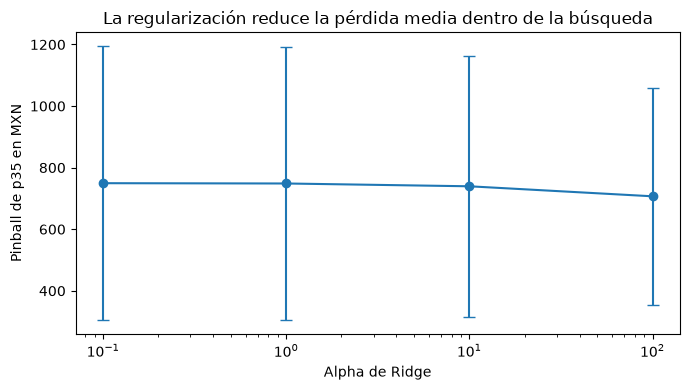

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(summary.index, summary.pinball, yerr=summary.desviacion, marker='o', capsize=4)
ax.set_xscale('log')
ax.set_xlabel('Alpha de Ridge')
ax.set_ylabel('Pinball de p35 en MXN')
ax.set_title('La regularización reduce la pérdida media dentro de la búsqueda')
plt.tight_layout()
plt.show()

Las barras representan desviación entre folds, no intervalos de confianza. Esta validación se usó para escoger alpha y no es una evaluación independiente. Los extremos se conservaron en las métricas.

Las métricas de esta búsqueda son provisionales: se calcularon con scikit-learn y funciones locales. Al integrar las métricas comunes de src.metrics, se deben regenerar los resultados de desarrollo antes de la comparación entre familias.

In [5]:
artifact = joblib.load(ROOT / 'models/ridge.joblib')
listing = json.loads((ROOT / 'examples/listing.json').read_text())
display(pd.Series(recommend(artifact['model'], listing)))

currency                                                           MXN
recommended_price                                              1320.86
lower_price                                                     885.35
upper_price                                                    3443.93
median_price                                                   1573.35
nominal_coverage                                                   0.8
note                 Referencia de precios publicados en CDMX; no g...
dtype: object

## Interpretación y limitaciones

- ¿Por qué logaritmos? Para modelar cambios relativos y reducir la influencia de la cola durante el ajuste; evaluamos en pesos originales.
- ¿Por qué Ridge? Es la regresión regularizada vista en clase y una referencia interpretable frente al boosting.
- ¿Por qué separar por anfitrión? Evita que anuncios del mismo operador se repartan entre entrenamiento y validación.
- ¿Por qué p35? Es una preferencia conservadora declarada; no un precio que hayamos probado que maximice ingresos.
- ¿Qué significa el rango? Es un rango predictivo aproximado de precios publicados, no un intervalo de confianza de una media.
- Evaluación pendiente: comparación entre familias de modelos, selección global y una evaluación final de septiembre.

El precio anunciado no prueba reservas. Un ID nuevo en el snapshot no demuestra un anfitrión realmente nuevo.

## Bitácora de colaboración con IA

- **Validación sin fugas:** Utilizamos IA para revisar la separación por `host_id` y que el preprocesamiento se ajustara dentro de cada fold.
- **Selección de Ridge:** Utilizamos IA para revisar la búsqueda de `alpha`, el uso de `log(precio)` y la evaluación del error nuevamente en MXN.
- **Recomendador:** Utilizamos IA para revisar la serialización con `joblib`, la validación de entradas y la interpretación de p10, p35, p50 y p90 sin usar septiembre.